# Part B：特征分布、相关性与多重共线性

使用 Part A 处理后的数据 `q1_clean.csv`（删除整套传感器缺失的 330 行 + KNN 填补 NOx/NO2，共 7344 行，无缺失）。

本 notebook 包括：
1. 每个变量的分布（直方图 + 偏度）
2. 相关系数热力图
3. 各特征与 CO 的相关性排序
4. 成对散点图（挑选主要变量）
5. 方差膨胀因子（VIF），检验多重共线性

> 只用到 numpy、pandas、matplotlib，不需要额外安装 seaborn / statsmodels。

In [2]:
%pip install numpy pandas matplotlib scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("q1.csv")      # Part A 的输出；如路径不同请修改
TARGET = "CO(GT)"
FEATURES = [c for c in df.columns if c != TARGET]
print(df.shape)
df.describe().T.round(2)

(7674, 12)


,count,mean,std,min,25%,50%,75%,max
CO(GT),7674.0,2.15,1.45,0.10,1.10,1.80,2.90,11.90
PT08.S1(CO),7344.0,1110.58,218.68,647.00,946.00,1075.00,1246.00,2040.00
C6H6(GT),7344.0,10.28,7.44,0.20,4.60,8.50,14.30,63.70
PT08.S2(NMHC),7344.0,947.20,265.47,387.00,743.00,919.00,1125.25,2214.00
NOx(GT),7261.0,255.31,215.35,2.00,103.00,188.00,339.00,1479.00
PT08.S3(NOx),7344.0,826.92,256.65,322.00,649.00,795.00,960.00,2683.00
NO2(GT),7258.0,114.81,48.24,2.00,80.00,110.00,144.00,340.00
PT08.S4(NO2),7344.0,1444.75,350.34,551.00,1203.00,1447.00,1673.00,2775.00
PT08.S5(O3),7344.0,1043.51,405.57,221.00,744.75,990.00,1305.00,2523.00
T,7344.0,17.77,8.86,-1.90,11.20,16.90,23.80,44.60


## 1. 分布

**偏度（skewness）**：衡量分布歪向哪一边。0 = 对称；> 1 = 明显右偏（大部分值偏小，偶尔有很大的值，右边拖着长尾巴）。

偏度:
NOx(GT)          1.67
CO(GT)           1.37
C6H6(GT)         1.33
PT08.S3(NOx)     1.15
PT08.S1(CO)      0.73
NO2(GT)          0.63
PT08.S5(O3)      0.58
PT08.S2(NMHC)    0.53
T                0.38
AH               0.34
PT08.S4(NO2)     0.22
RH              -0.01


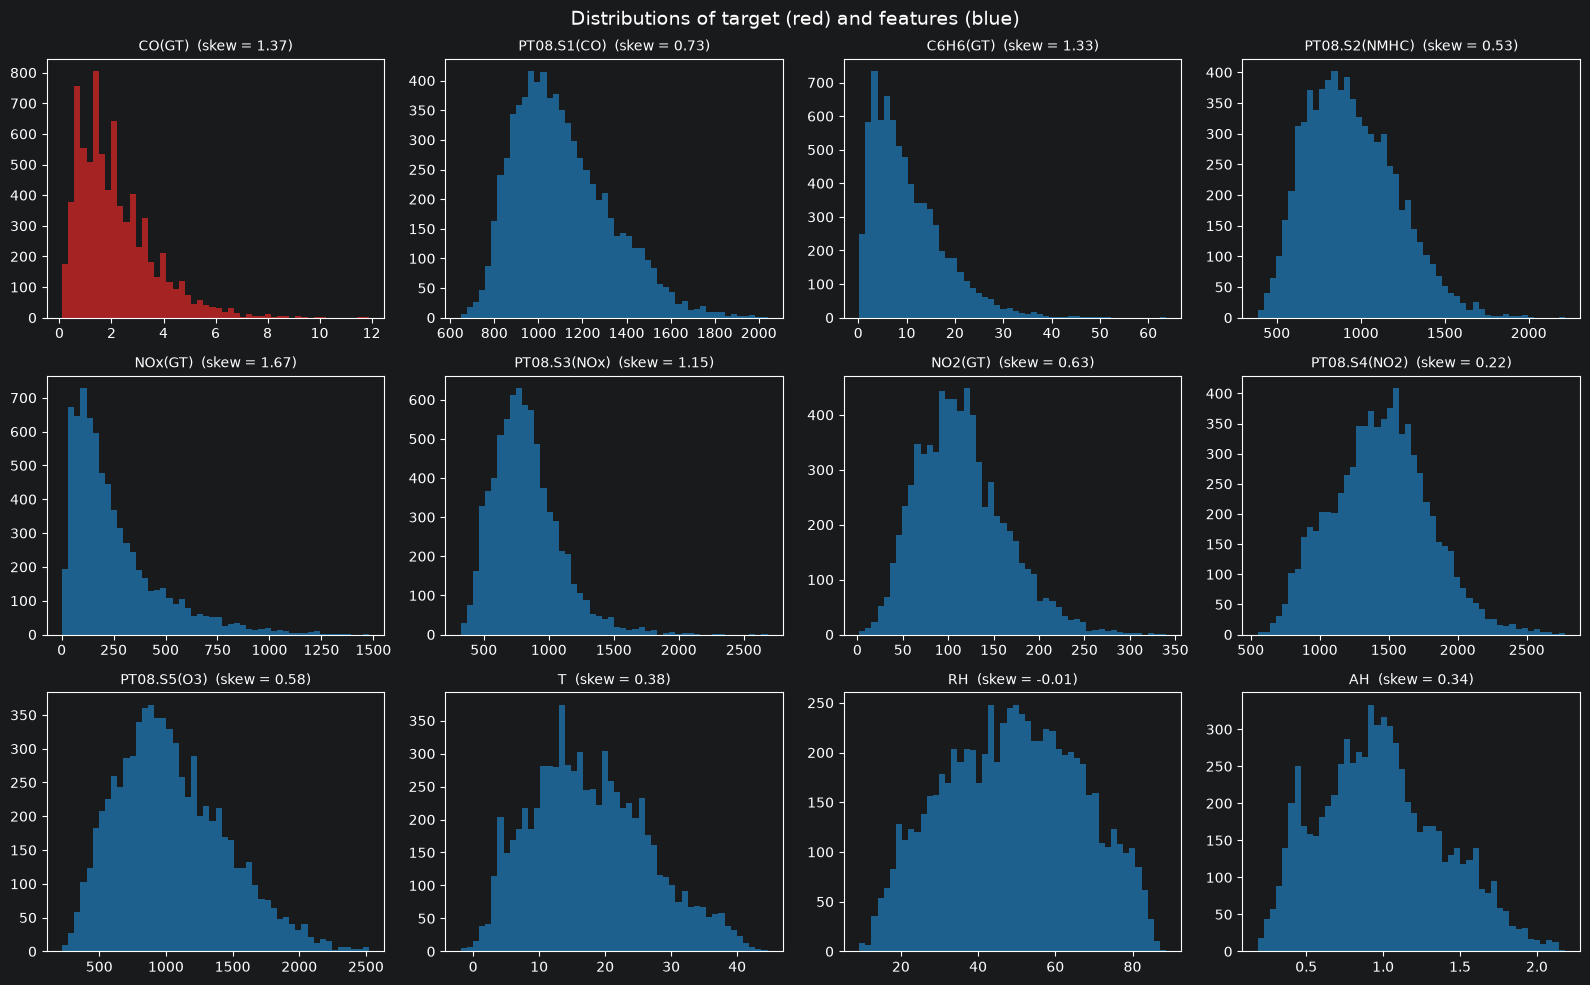

In [6]:
skew = df.skew().round(2).sort_values(ascending=False)
print("偏度:")
print(skew.to_string())

cols = [TARGET] + FEATURES
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), cols):
    ax.hist(df[col], bins=50, color="tab:red" if col == TARGET else "tab:blue", alpha=0.75)
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})", fontsize=10)
fig.suptitle("Distributions of target (red) and features (blue)", fontsize=14)
plt.tight_layout()
plt.show()

## 2. 相关系数热力图

数字范围 −1 到 1：越接近 ±1，两个变量越"同涨同跌"（负数表示一涨一跌）。只反映**直线关系**。

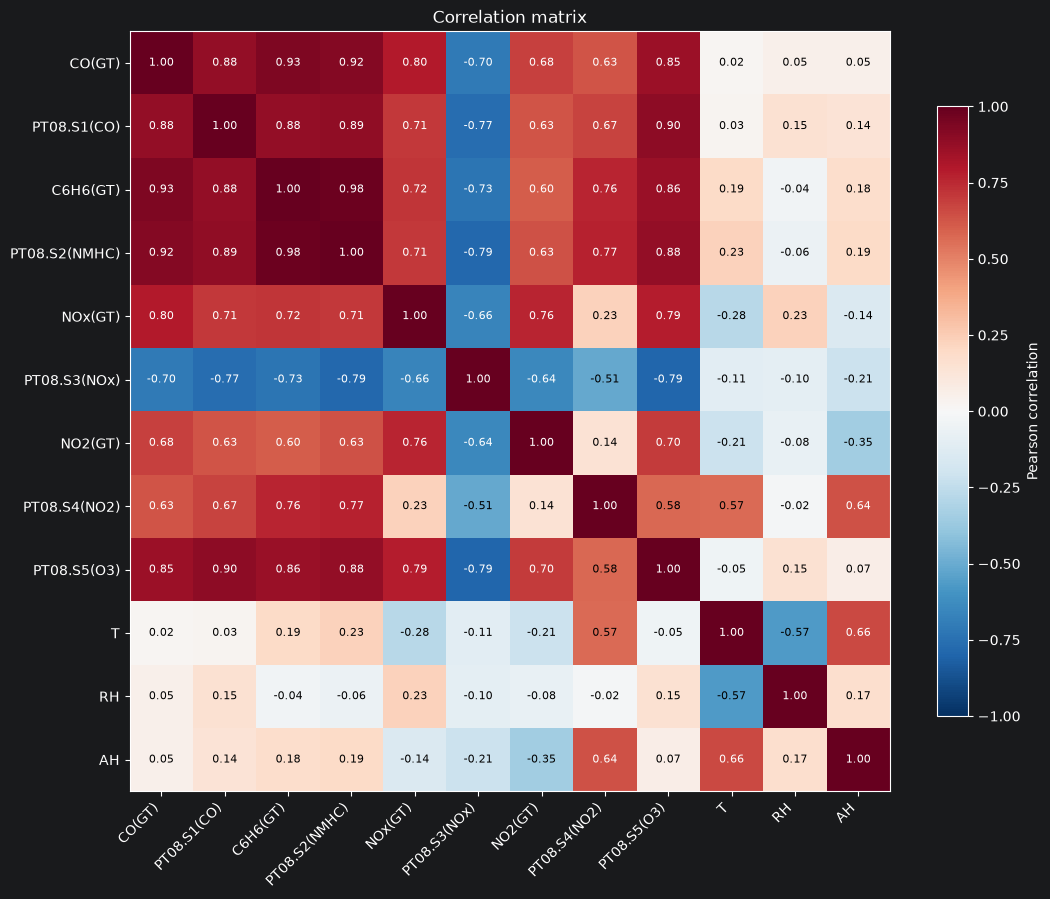

In [7]:
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

## 3. 各特征与 CO 的相关性

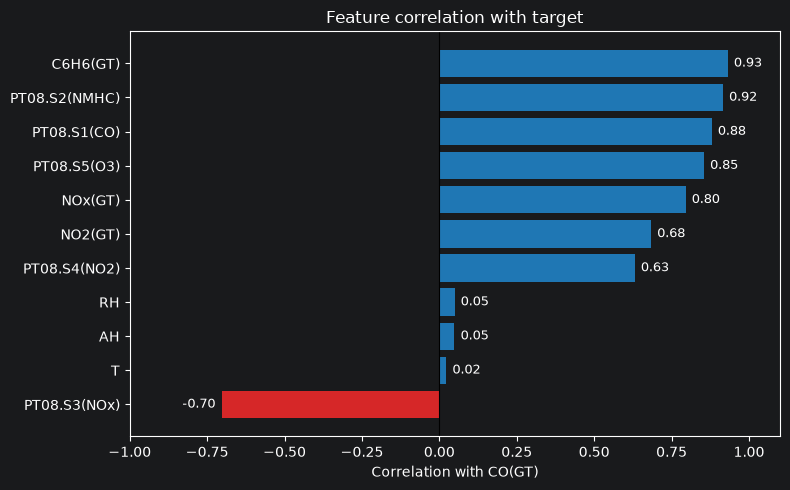

In [8]:
corr_target = corr[TARGET].drop(TARGET).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["tab:red" if v < 0 else "tab:blue" for v in corr_target]
ax.barh(corr_target.index, corr_target.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
for y, v in enumerate(corr_target.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(-1, 1.1)
ax.set_xlabel("Correlation with CO(GT)")
ax.set_title("Feature correlation with target")
plt.tight_layout()
plt.show()

### 特征之间的强相关对（|r| > 0.8）

这些是多重共线性的直接信号：两个特征几乎在讲同一件事。

In [9]:
fc = df[FEATURES].corr()
pairs = [(a, b, fc.loc[a, b])
         for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]
         if abs(fc.loc[a, b]) > 0.8]
strong = (pd.DataFrame(pairs, columns=["feature_1", "feature_2", "r"])
          .sort_values("r", key=abs, ascending=False)
          .round(3).reset_index(drop=True))
strong

,feature_1,feature_2,r
0,C6H6(GT),PT08.S2(NMHC),0.982
1,PT08.S1(CO),PT08.S5(O3),0.898
2,PT08.S1(CO),PT08.S2(NMHC),0.888
3,PT08.S1(CO),C6H6(GT),0.879
4,PT08.S2(NMHC),PT08.S5(O3),0.877
5,C6H6(GT),PT08.S5(O3),0.862


## 4. 成对散点图（主要变量）

11 个特征全画会太挤，这里挑与 CO 相关最强的几个，再加上温度。对角线是各变量的直方图，其余每格是两两散点图。可以看到相关是否为直线、有没有弯曲或极端值。

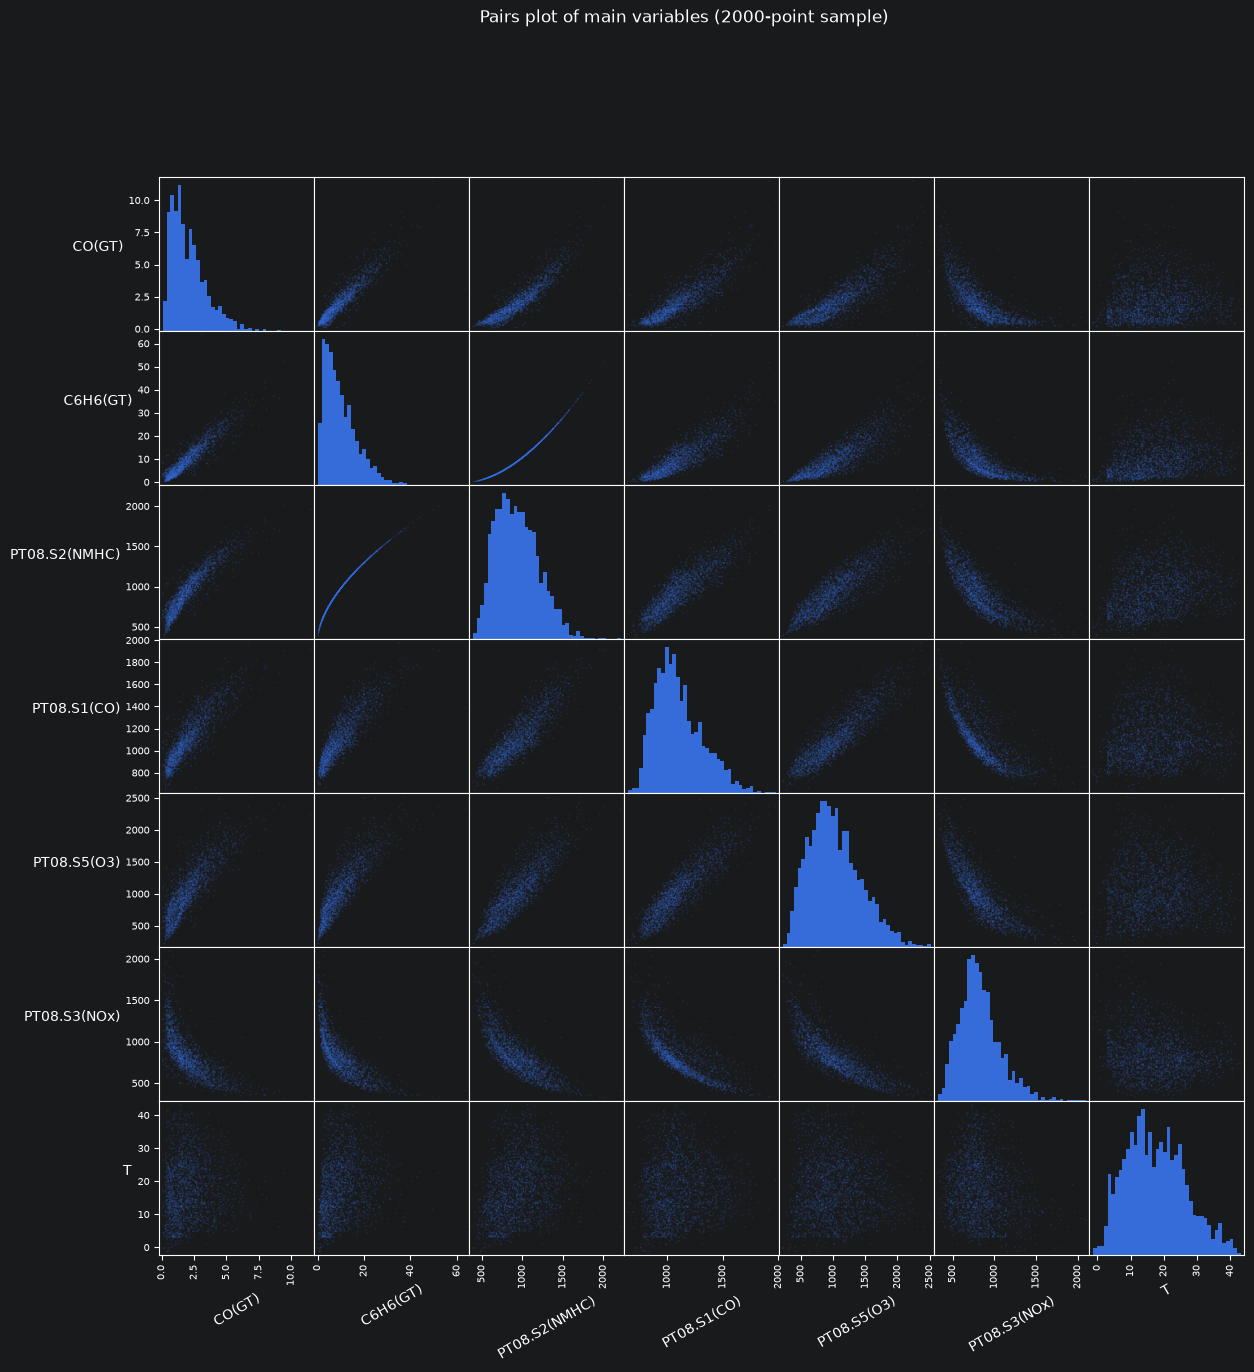

In [10]:
main_vars = [TARGET, "C6H6(GT)", "PT08.S2(NMHC)", "PT08.S1(CO)", "PT08.S5(O3)", "PT08.S3(NOx)", "T"]

sample = df[main_vars].sample(2000, random_state=0)   # 抽样 2000 点，避免图太密、太慢
axes = pd.plotting.scatter_matrix(sample, figsize=(14, 14), alpha=0.2, s=5,
                                  diagonal="hist", hist_kwds={"bins": 40})
for ax in axes.ravel():
    ax.xaxis.label.set_rotation(30)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_ha("right")
    ax.tick_params(labelsize=7)
plt.suptitle("Pairs plot of main variables (2000-point sample)", y=1.0)
plt.show()

## 5. 方差膨胀因子（VIF）

热力图一次只看**两个**变量。有些共线性要**几个变量合起来**才出现（例如 AH 由 T 和 RH 算出）。

**VIF** 衡量"一个特征能被其他所有特征一起解释到什么程度"：
- VIF = 1：完全独立
- VIF > 5：值得注意
- VIF > 10：严重共线

计算方法：VIF 等于特征相关矩阵的逆矩阵的对角线元素（与"对每个特征用其余特征做回归，VIF = 1/(1−R²)"等价）。

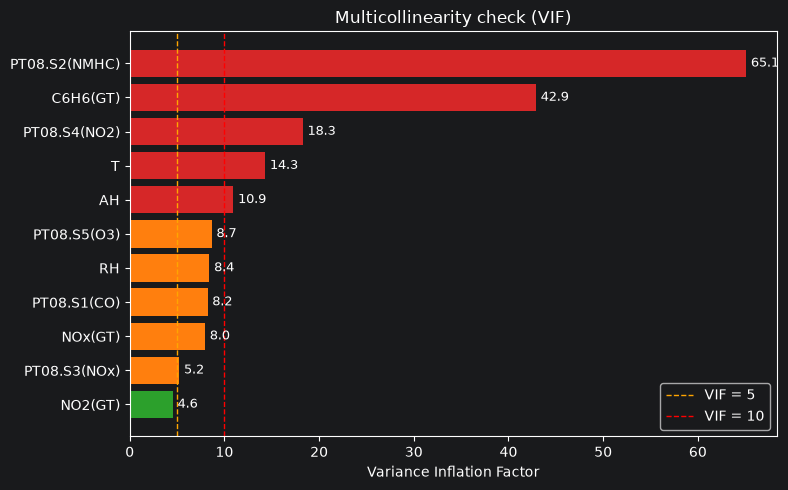

,VIF
PT08.S2(NMHC),65.1
C6H6(GT),42.9
PT08.S4(NO2),18.3
T,14.3
AH,10.9
PT08.S5(O3),8.7
RH,8.4
PT08.S1(CO),8.2
NOx(GT),8.0
PT08.S3(NOx),5.2


In [11]:
inv_corr = np.linalg.inv(df[FEATURES].corr().values)
vif = pd.Series(np.diag(inv_corr), index=FEATURES, name="VIF").sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["tab:red" if v > 10 else ("tab:orange" if v > 5 else "tab:green") for v in vif]
ax.barh(vif.index[::-1], vif.values[::-1], color=colors[::-1])
ax.axvline(5, ls="--", c="orange", lw=1, label="VIF = 5")
ax.axvline(10, ls="--", c="red", lw=1, label="VIF = 10")
for y, v in enumerate(vif.values[::-1]):
    ax.text(v + 0.5, y, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlabel("Variance Inflation Factor")
ax.set_title("Multicollinearity check (VIF)")
ax.legend()
plt.tight_layout()
plt.show()

vif.round(1).to_frame()

## 6. 结论（请核对你跑出的数字）

**与 CO 的相关性**
- 苯 C6H6(GT)（0.93）、PT08.S2(NMHC)（0.92）、PT08.S1(CO)（0.88）、PT08.S5(O3)（0.85）与 CO 强正相关。这些污染物主要来自同一来源（交通尾气），因此同涨同跌。
- PT08.S3(NOx) 呈强负相关（−0.70）：这类金属氧化物传感器在污染越重时电阻越低，读数反而下降，不是数据错误。
- 温度、湿度与 CO 几乎无线性相关（≈ 0），但可能影响传感器读数，不代表在模型中完全无用。

**多重共线性**
- C6H6(GT) 与 PT08.S2(NMHC) 相关系数达 0.98，几乎是同一个信号；PT08.S1、S2、S5 与苯之间也普遍在 0.86–0.90。
- VIF 显示 PT08.S2(NMHC)（≈ 65）和 C6H6(GT)（≈ 43）共线性极其严重，PT08.S4(NO2)、T、AH 的 VIF 也超过 10。
- T 和 AH 在热力图上两两相关不突出，但 VIF 超过 10：因为绝对湿度由温度和相对湿度共同决定，属于"多变量合起来"的共线性，单看热力图会漏掉。

**分布**
- CO、NOx(GT)、C6H6(GT) 明显右偏：大部分时间浓度较低，偶有高峰。可考虑取对数，但非必须。

**对后续的影响**
- 严重的多重共线性会让 C 题的普通最小二乘（OLS）回归系数不稳定（数值巨大、正负抵消、p 值很大），这正是 D 题使用 Ridge / Lasso 正则化的动机。